# Clustering: Wholesale Customers

**Problem statement:** Segment customers using six annual-spending features. `Channel` and `Region` are used only after fitting for interpretation.

## 1. Setup and reproducibility

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

RANDOM_STATE=42; 
np.random.seed(RANDOM_STATE); 
sns.set_theme(style="whitegrid",palette="colorblind")

FEATURES=["Fresh","Milk","Grocery","Frozen","Detergents_Paper","Delicassen"]

def metrics(x,y): 
   return {"Silhouette Score":silhouette_score(x,y), "Davies-Bouldin Index": davies_bouldin_score(x,y), "Calinski-Harabasz Index": calinski_harabasz_score(x,y)}

def pca_plot(x,y,title):
 z = PCA(2,random_state=RANDOM_STATE).fit_transform(x); 
 q=pd.DataFrame({"PC1":z[:,0],"PC2":z[:,1],"Cluster":y.astype(str)})
 plt.figure(figsize=(8,6)); 
 sns.scatterplot(data=q,x="PC1",y="PC2",hue="Cluster",palette="tab10",s=55); 
 plt.title(title); 
 plt.xlabel("Principal component 1"); 
 plt.ylabel("Principal component 2"); 
 plt.legend(title="Cluster"); 
 plt.tight_layout(); 
 plt.show()

## 2. Dataset loading and audit

In [2]:
data_path = Path("data/clustering.csv")
if not data_path.exists(): 
    data_path = Path("../data/clustering.csv")
df = pd.read_csv(data_path) 
display(df.head()) 
print(f"Dataset shape: {df.shape}")
audit = pd.DataFrame({"dtype":df.dtypes.astype(str),"missing_count":df.isna().sum(),"missing_percent":df.isna().mean().mul(100).round(2),"unique_values":df.nunique()})
display(audit) 
print("Duplicate rows:",df.duplicated().sum())

,Channel,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Region
0,2,12669,9656,7561,214,2674,1338,3
1,2,7057,9810,9568,1762,3293,1776,3
2,2,6353,8808,7684,2405,3516,7844,3
3,1,13265,1196,4221,6404,507,1788,3
4,2,22615,5410,7198,3915,1777,5185,3


Dataset shape: (440, 8)


,dtype,missing_count,missing_percent,unique_values
Channel,int64,0,0.0,2
Fresh,int64,0,0.0,433
Milk,int64,0,0.0,421
Grocery,int64,0,0.0,430
Frozen,int64,0,0.0,426
Detergents_Paper,int64,0,0.0,417
Delicassen,int64,0,0.0,403
Region,int64,0,0.0,3


Duplicate rows: 0


**Observation:** There are 440 customers, no missing values, and no duplicate rows. The six spending columns are the only fitting inputs; `Channel` and `Region` remain reference fields.

## 3. Spending distributions, transformation and scaling

All spending features are non-negative, right-skewed monetary values. We retain outliers because they may be real customer segments, then apply `log1p` and `StandardScaler` so a few large spenders do not dominate Euclidean distances. No train/test split is needed: clustering has no label to predict, and one scaler defines the shared distance space for all rows rather than leaking labels.

,original_skew,log1p_skew
Fresh,2.56,-1.58
Milk,4.05,-0.22
Grocery,3.59,-0.67
Frozen,5.91,-0.35
Detergents_Paper,3.63,-0.24
Delicassen,11.15,-1.09


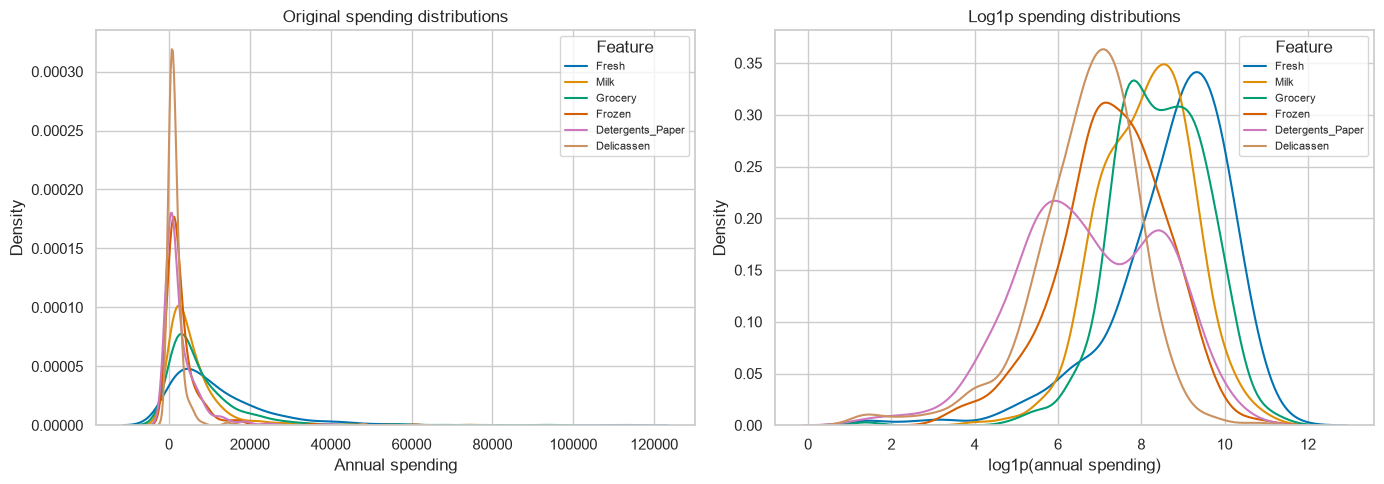

In [3]:
skew = pd.DataFrame({"original_skew":df[FEATURES].skew(),"log1p_skew":np.log1p(df[FEATURES]).skew()}).round(2) 
display(skew)
fig,ax = plt.subplots(1,2,figsize=(14,5))

for f in FEATURES: 
    sns.kdeplot(df[f],ax=ax[0],label=f) 
    sns.kdeplot(np.log1p(df[f]),ax=ax[1],label=f)

ax[0].set(title = "Original spending distributions",xlabel="Annual spending",ylabel="Density")
ax[1].set(title="Log1p spending distributions",xlabel="log1p(annual spending)",ylabel="Density")

for a in ax:
    a.legend(title="Feature",fontsize=8)

plt.tight_layout()
plt.show()
X = StandardScaler().fit_transform(np.log1p(df[FEATURES]))

**Observation:** `Delicassen` and the other original features have long right tails; logging noticeably reduces their skewness while keeping every customer.

## 4. K-Means: selecting the number of clusters

K-Means is fit only on transformed spending features. The elbow is assessed alongside silhouette for `k=2` through `10`, because an elbow alone can be ambiguous.

,k,inertia,silhouette
0,2,1844.064,0.290
1,3,1553.413,0.258
2,4,1386.863,0.188
3,5,1266.149,0.192
4,6,1174.536,0.195
5,7,1086.359,0.196
6,8,1024.047,0.191
7,9,973.141,0.197
8,10,931.998,0.191


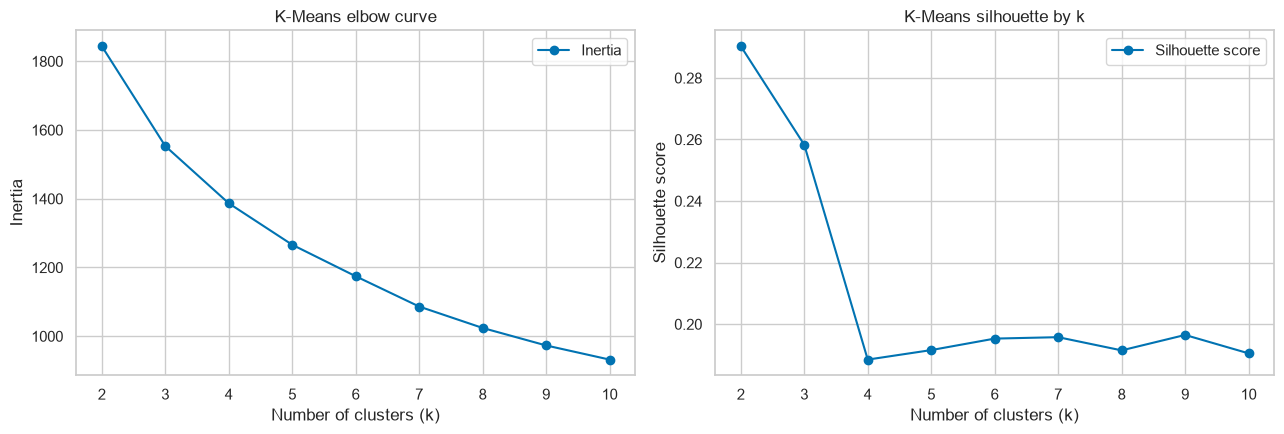

In [4]:
sel = []

for k in range(2,11):
 y = KMeans(k,random_state=RANDOM_STATE,n_init=20).fit_predict(X)
 sel.append((k,KMeans(k,random_state=RANDOM_STATE,n_init=20).fit(X).inertia_,silhouette_score(X,y)))
 
sel = pd.DataFrame(sel,columns=["k","inertia","silhouette"]) 

display(sel.round(3))
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
ax[0].plot(sel.k,sel.inertia,"o-",label="Inertia")
ax[0].set(title="K-Means elbow curve",xlabel="Number of clusters (k)",ylabel="Inertia")
ax[0].legend()
ax[1].plot(sel.k,sel.silhouette,"o-",label="Silhouette score") 
ax[1].set(title="K-Means silhouette by k",xlabel="Number of clusters (k)",ylabel="Silhouette score")
ax[1].legend() 
plt.tight_layout()
plt.show()
K = 2
km = KMeans(K,random_state=RANDOM_STATE,n_init=20)
km_y=km.fit_predict(X)

**Observation:** `k=2` gives the clearest elbow and strongest silhouette, so it is selected as the most stable and interpretable segmentation.

## 5. Agglomerative hierarchical clustering

A Ward dendrogram and Ward, complete, average, and single-linkage models are compared at the same selected `k=2`.

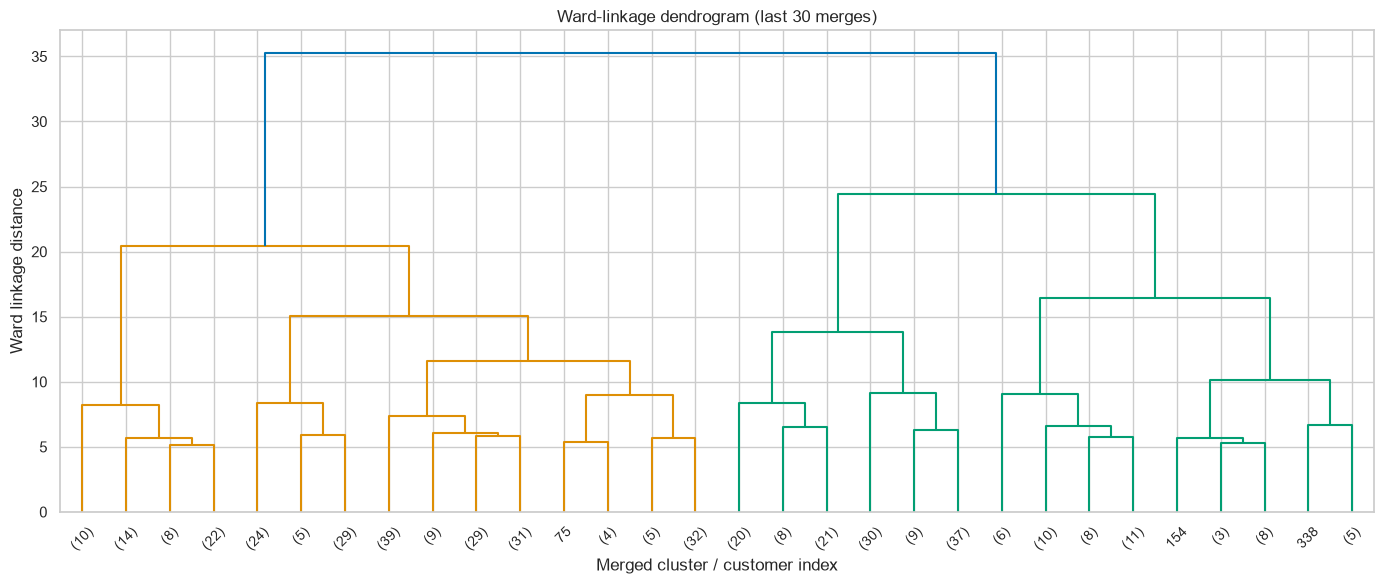

,Model,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Cluster sizes
0,"Agglomerative (ward, k=2)",0.258,1.600,134.624,"(178, 262)"
1,"Agglomerative (complete, k=2)",0.322,1.554,61.992,"(38, 402)"
2,"Agglomerative (average, k=2)",0.569,0.883,13.965,"(2, 438)"
3,"Agglomerative (single, k=2)",0.570,0.307,8.964,"(439, 1)"


In [5]:
Z=linkage(X,method="ward")
plt.figure(figsize=(14,6))
dendrogram(Z,truncate_mode="lastp",p=30)
plt.title("Ward-linkage dendrogram (last 30 merges)")
plt.xlabel("Merged cluster / customer index")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()
rows = [{"Model":"K-Means (k=2)",**metrics(X,km_y)}]
ag = {}

for link in ["ward","complete","average","single"]:
 y = AgglomerativeClustering(K,linkage=link).fit_predict(X)
 ag[link]=y
 rows.append({"Model":f"Agglomerative ({link}, k=2)",**metrics(X,y),"Cluster sizes":tuple(np.bincount(y))})

linkage_table = pd.DataFrame(rows[1:])
display(linkage_table.round(3))
ward_y = ag["ward"]


**Observation:** The higher final Ward merge distances support a coarse two-group cut. Single linkage tends to chain customers into one giant group, which its cluster sizes help reveal.

## 6. Cluster visualisation

PCA is a two-dimensional inspection of models fitted in all six transformed dimensions; t-SNE is a complementary non-linear visualisation, not a model-selection criterion.

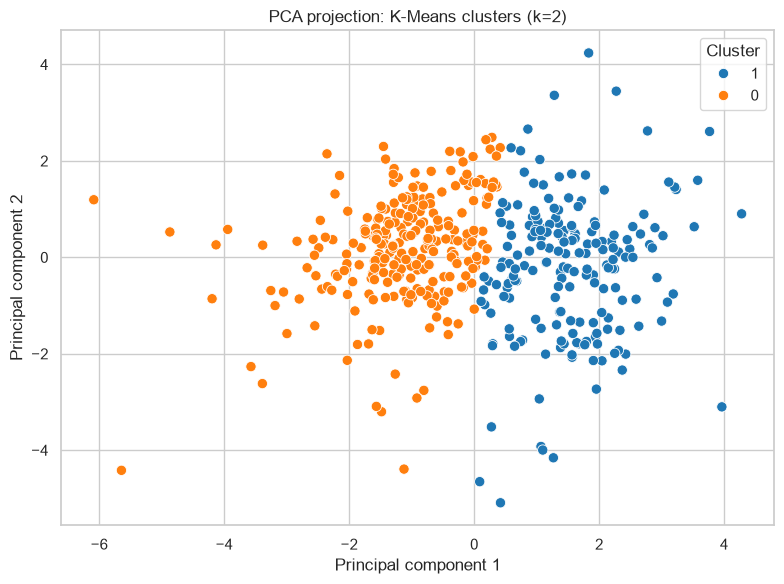

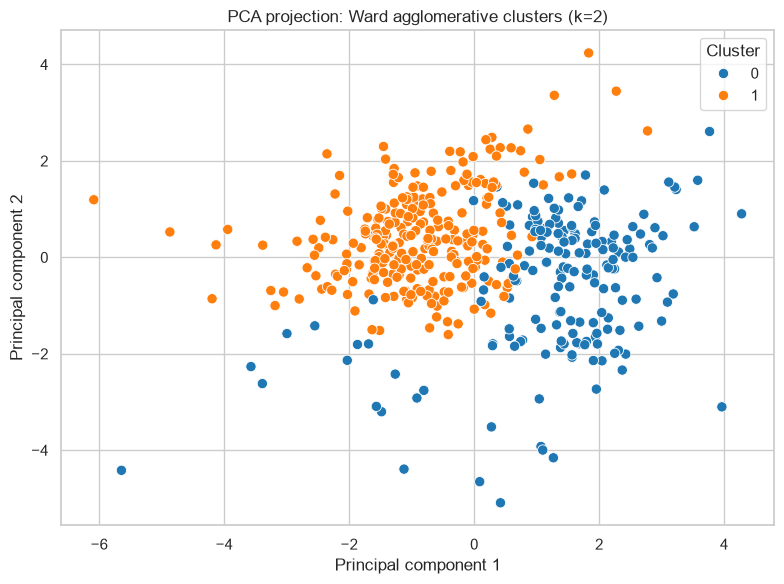

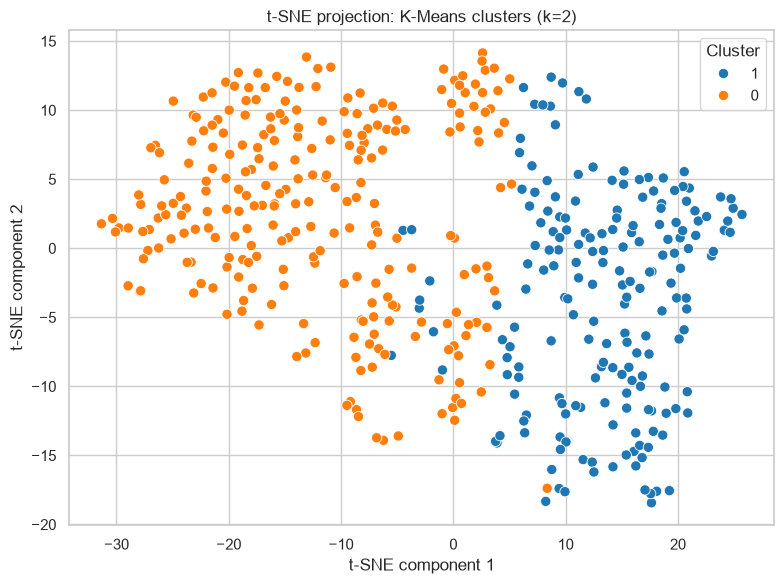

In [6]:
pca_plot(X,km_y,"PCA projection: K-Means clusters (k=2)")
pca_plot(X,ward_y,"PCA projection: Ward agglomerative clusters (k=2)")
t = TSNE(2,perplexity=30,init="pca",learning_rate="auto",random_state=RANDOM_STATE).fit_transform(X) 
q = pd.DataFrame({"t-SNE 1":t[:,0],"t-SNE 2":t[:,1],"Cluster":km_y.astype(str)}) 
plt.figure(figsize=(8,6))
sns.scatterplot(data=q,x="t-SNE 1",y="t-SNE 2",hue="Cluster",palette="tab10",s=55)
plt.title("t-SNE projection: K-Means clusters (k=2)")
plt.xlabel("t-SNE component 1")
plt.ylabel("t-SNE component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

**Observation:** PCA and t-SNE provide consistent visual checks of the fitted labels, but projected overlap is interpreted cautiously because both are lower-dimensional displays.

## 7. Model comparison, stability and interpretation

All internal metrics are collected in one table. Repeated 80% subsampling is the clustering-specific substitute for cross-validation, since clustering has no held-out target performance.

In [7]:
summary = pd.DataFrame(rows) 
display(summary.drop(columns="Cluster sizes",errors="ignore").round(3))
st = [] 
rng = np.random.RandomState(RANDOM_STATE)

for name,link in [("K-Means",None),("Agglomerative (ward)","ward")]:
 scores = []
 for _ in range(5):
  ix = rng.choice(len(X),352,replace=False) 
  xs = X[ix]
  y = KMeans(K,random_state=RANDOM_STATE,n_init=20).fit_predict(xs) if link is None else AgglomerativeClustering(K,linkage=link).fit_predict(xs)
  scores.append(silhouette_score(xs,y))
 st.append((name,np.mean(scores),np.std(scores)))

display(pd.DataFrame(st,columns=["Model","Silhouette mean","Silhouette std"]).round(3))
z = df.copy()
z["K-Means cluster"] = km_y
display(z.groupby("K-Means cluster")[FEATURES].median().round(0))
display(pd.crosstab(z["K-Means cluster"],z.Channel,normalize="index").mul(100).round(1))
print("Adjusted Rand index against Channel (post-hoc only):",round(adjusted_rand_score(df.Channel,km_y),3))

,Model,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means (k=2),0.290,1.352,189.050
1,"Agglomerative (ward, k=2)",0.258,1.600,134.624
2,"Agglomerative (complete, k=2)",0.322,1.554,61.992
3,"Agglomerative (average, k=2)",0.569,0.883,13.965
4,"Agglomerative (single, k=2)",0.570,0.307,8.964


,Model,Silhouette mean,Silhouette std
0,K-Means,0.287,0.004
1,Agglomerative (ward),0.255,0.020


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
K-Means cluster,,,,,,
0,10348.0,1871.0,2406.0,2225.0,328.0,750.0
1,5406.0,7690.0,11527.0,1062.0,4495.0,1388.0


Channel,1,2
K-Means cluster,,
0,96.8,3.2
1,28.7,71.3


Adjusted Rand index against Channel (post-hoc only): 0.514


**Observation:** The single comparison table reports all required internal metrics for every model. The repeated subsamples measure stability, while original-unit medians and the Channel crosstab interpret the final K-Means groups without using labels during fitting.

## 8. Conclusion

Log-transforming and scaling all six spending variables preserves customers while supporting distance-based clustering. K-Means and Ward hierarchical clustering at `k=2` offer complementary, reproducible segmentations; Channel is only a post-hoc validation reference.